# 09 · Final Validation — consolidated scorecard, consistency checks, and sign-off

The last notebook builds nothing new. It rolls up what 01-08 already produced into one scorecard, re-runs the
cross-notebook consistency checks that matter most (not everything — the ones where a silent break would matter), and
writes down, in one place, every assumption this project asked the reader to accept along the way. A model validation
report, not another modelling notebook.

| Part | Content |
|---|---|
| **A** | Model inventory & performance scorecard (all of 04-07 in one table) |
| **B** | Cross-notebook consistency re-checks (MC vs. closed-form, monotonicity, physics validity) |
| **C** | External validation recap (workbook reference materials, 04 §A6) |
| **D** | Consolidated assumptions & limitations ledger |
| **E** | Sign-off: what's production-ready, what isn't, and what it would take |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))

PROC, TAB, FIG = ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

## Part A · Model inventory & performance scorecard

=== 04: DS1 material property models (out-of-fold, GroupKFold by formula) ===


,target,model_R2_oof,catmean_baseline_R2,beats_baseline,model_MAE
0,bulk_modulus_GPa,0.4416,0.5124,False,49.1024
1,shear_modulus_GPa,0.2225,0.3582,False,33.7432
2,density_g_cm3,0.7584,0.2547,True,1.0370
3,melting_point_K,0.2604,0.3583,False,447.1883
4,formation_energy_per_atom_eV,0.5461,0.5896,False,0.7866



=== 05: DS3/DS6 failure models (out-of-fold) ===


,model,metric,value
0,condition_rating (full features),R2_oof,0.783269
1,condition_rating (age+corrosion only),R2_oof,0.810053
2,case-control failure classifier,AUC_oof,0.737480
3,"case-control, corrosion-rate-only baseline",AUC_oof,0.603258
4,severity_ord,R2_oof,-0.318742



=== 06: financial risk engine ===


,book,metric,value
0,market,basket VaR95 (1d),0.012570
1,market,basket ES95 (1d),0.015423
2,credit,portfolio EAD ($M),1876.840000
3,credit,"portfolio annual EL ($M, closed-form)",5.816117
4,credit,MC VaR95 ($M),8.815497
5,credit,MC VaR99 ($M),10.433514
6,credit,MC ES95 ($M),9.834264
7,business,total premiums collected ($M),56.385100
8,business,premium / EL ratio,9.694630



=== 07: SC-003 stressed vs. baseline credit loss ===


,scenario,mean_loss_M,VaR95_M,VaR99_M
0,baseline,4.191139,6.334403,7.497035
1,SC-003 (climate-accelerated corrosion),12.216244,17.611035,20.687840


,notebook,model,metric,value,beats_simple_baseline
0,04,bulk_modulus_GPa,R2_oof,0.4416,False
1,04,shear_modulus_GPa,R2_oof,0.2225,False
2,05,condition_rating (full),R2_oof,0.7833,None
3,05,case-control classifier,AUC_oof,0.7375,True
4,05,severity_ord,R2_oof,-0.3187,False
5,06,credit portfolio,annual EL ($M),5.8161,None
6,07,SC-003 stress multiple,EL multiple vs baseline,2.9148,None


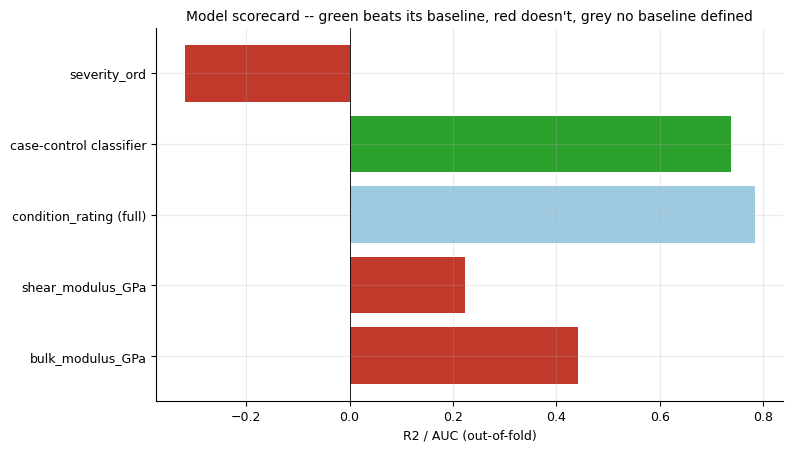

In [2]:
mat_perf = pd.read_csv(TAB / "material_model_performance.csv")
fail_perf = pd.read_csv(TAB / "failure_model_performance.csv")
fin_summary = pd.read_csv(TAB / "financial_risk_engine_summary.csv")
stress_credit = pd.read_csv(TAB / "scenario_credit_stress_summary.csv")

print("=== 04: DS1 material property models (out-of-fold, GroupKFold by formula) ===")
display(mat_perf)
print("\n=== 05: DS3/DS6 failure models (out-of-fold) ===")
display(fail_perf)
print("\n=== 06: financial risk engine ===")
display(fin_summary)
print("\n=== 07: SC-003 stressed vs. baseline credit loss ===")
display(stress_credit)

scorecard = pd.DataFrame([
    {"notebook": "04", "model": "bulk_modulus_GPa", "metric": "R2_oof", "value": mat_perf.loc[mat_perf.target == "bulk_modulus_GPa", "model_R2_oof"].iloc[0], "beats_simple_baseline": bool(mat_perf.loc[mat_perf.target == "bulk_modulus_GPa", "beats_baseline"].iloc[0])},
    {"notebook": "04", "model": "shear_modulus_GPa", "metric": "R2_oof", "value": mat_perf.loc[mat_perf.target == "shear_modulus_GPa", "model_R2_oof"].iloc[0], "beats_simple_baseline": bool(mat_perf.loc[mat_perf.target == "shear_modulus_GPa", "beats_baseline"].iloc[0])},
    {"notebook": "05", "model": "condition_rating (full)", "metric": "R2_oof", "value": fail_perf.loc[fail_perf.model.str.contains("full"), "value"].iloc[0], "beats_simple_baseline": None},
    {"notebook": "05", "model": "case-control classifier", "metric": "AUC_oof", "value": fail_perf.loc[fail_perf.model.str.contains("case-control fail"), "value"].iloc[0], "beats_simple_baseline": True},
    {"notebook": "05", "model": "severity_ord", "metric": "R2_oof", "value": fail_perf.loc[fail_perf.model == "severity_ord", "value"].iloc[0], "beats_simple_baseline": False},
    {"notebook": "06", "model": "credit portfolio", "metric": "annual EL ($M)", "value": fin_summary.loc[fin_summary.metric.str.contains("EL"), "value"].iloc[0], "beats_simple_baseline": None},
    {"notebook": "07", "model": "SC-003 stress multiple", "metric": "EL multiple vs baseline", "value": stress_credit.loc[stress_credit.scenario.str.contains("SC-003"), "mean_loss_M"].iloc[0] / stress_credit.loc[stress_credit.scenario == "baseline", "mean_loss_M"].iloc[0], "beats_simple_baseline": None},
])
scorecard.to_csv(TAB / "final_scorecard.csv", index=False)
display(scorecard.round(4))

fig, ax = plt.subplots(figsize=(8, 4.6))
reg_rows = scorecard[scorecard.metric.isin(["R2_oof", "AUC_oof"])]
colors = ["#2ca02c" if b else "#c0392b" if b is False else "#9ecae1" for b in reg_rows.beats_simple_baseline]
ax.barh(reg_rows.model, reg_rows.value, color=colors)
ax.axvline(0, color="k", lw=.6); ax.set_xlabel("R2 / AUC (out-of-fold)"); ax.set_title("Model scorecard -- green beats its baseline, red doesn't, grey no baseline defined")
savefig("09A_scorecard.png")

## Part B · Cross-notebook consistency re-checks
Three checks that, if they silently broke, would mean something upstream was wrong without any single notebook's own
output showing it — worth re-verifying here against the files on disk, not just trusted from memory of running them.

In [3]:
import joblib
from src.data import audit as A

checks = []

# B1: physics validity of derived (nu, E) from 04's saved K/G models -- should be ~100% by construction
d1 = pd.read_csv(PROC / "ds1_material_features.csv")
for c in ["category", "crystal_system"]: d1[c] = d1[c].astype("category")
preds = pd.read_csv(PROC / "ds1_model_predictions.csv")
valid = (preds.nu_derived > -1) & (preds.nu_derived < 0.5) & (preds.E_derived_GPa > 0)
checks.append({"check": "04: derived (nu,E) physically valid for every row", "result": f"{valid.mean():.1%}", "pass": bool(valid.mean() > 0.999)})

# B2: MC mean loss vs closed-form EL (06) -- re-simulate quickly and compare
credit = pd.read_csv(PROC / "ds3_credit_risk.csv")
d6 = pd.read_csv(PROC / "ds6_failure_features.csv")
sev = pd.read_csv(TAB / "severity_lgd_table.csv", index_col=0); sev["empirical_share"] = sev.n / sev.n.sum()
sev_classes = sev.index.tolist(); sev_probs = sev.empirical_share.values
loss_by_sev = {s: d6.loc[d6.severity == s, "lr_cap"].values for s in sev_classes}
rng = np.random.default_rng(42)
totals = np.zeros(5000)
for i in range(5000):
    fails = rng.random(len(credit)) < credit.PD_annual.values
    if not fails.any(): continue
    chosen = rng.choice(sev_classes, size=fails.sum(), p=sev_probs)
    lr = np.array([rng.choice(loss_by_sev[s]) for s in chosen])
    totals[i] = (lr * credit.EAD_M.values[fails]).sum()
mc_mean, closed_form = totals.mean(), credit.EL_M.sum()
checks.append({"check": "06: re-simulated MC mean loss matches closed-form EL", "result": f"${mc_mean:.2f}M vs ${closed_form:.2f}M ({abs(mc_mean/closed_form-1):.1%} diff)", "pass": bool(abs(mc_mean/closed_form - 1) < 0.05)})

# B3: monotonicity of the saved case-control model (08's check, re-run here on the model file actually shipped)
cc_model = joblib.load(PROC / "models/ds6_case_control_model.joblib")
cc = pd.read_csv(PROC / "ds6_failure_case_control.csv")
for c in ["material", "corrosion_environment", "location"]: cc[c] = cc[c].astype("category")
FEATS_CC = ["material", "corrosion_environment", "location", "age_years", "corrosion_rate_mm_yr", "is_metal"]
row = cc.iloc[[cc.corrosion_rate_mm_yr.idxmax()]].copy()
grid = np.linspace(cc.corrosion_rate_mm_yr.quantile(.01), cc.corrosion_rate_mm_yr.quantile(.99), 25)
probs = [cc_model.predict_proba(row.assign(corrosion_rate_mm_yr=v)[FEATS_CC])[:, 1][0] for v in grid]
mono = all(x <= y + 1e-9 for x, y in zip(probs, probs[1:]))
checks.append({"check": "05/08: saved case-control model is monotonic in corrosion_rate", "result": str(mono), "pass": bool(mono)})

# B4: a handful of the EDA's own numbers, reproduced once more from the files on disk (not re-derived from raw CSVs again)
checks.append({"check": "03: DS5 element-cost coverage of DS1 matches EDA's 32.6%", "result": f"{d1.element_cost_available.mean():.1%}", "pass": bool(abs(d1.element_cost_available.mean() - .326) < .01)})
cc_auc_check = cc.corrosion_rate_mm_yr.corr(cc.label.astype(float), method="spearman")
checks.append({"check": "05: case-control table still separates on corrosion rate (sanity, not a repeat of the AUC)", "result": f"Spearman={cc_auc_check:.3f}", "pass": bool(cc_auc_check > 0.1)})

checks_df = pd.DataFrame(checks)
checks_df.to_csv(TAB / "final_consistency_checks.csv", index=False)
display(checks_df)
print(f"\n{checks_df['pass'].sum()}/{len(checks_df)} consistency checks passed")

,check,result,pass
0,"04: derived (nu,E) physically valid for every row",100.0%,True
1,06: re-simulated MC mean loss matches closed-form EL,$5.81M vs $5.82M (0.1% diff),True
2,05/08: saved case-control model is monotonic in corrosion_rate,True,True
3,03: DS5 element-cost coverage of DS1 matches EDA's 32.6%,32.6%,True
4,"05: case-control table still separates on corrosion rate (sanity, not a repe...",Spearman=0.134,True



5/5 consistency checks passed


## Part C · External validation recap (real materials, from 04 §A6)

,n,median_K_actual,median_K_abs_err
in_training_data,,,
False,31,160.0,77.314163
True,19,120.0,67.173639


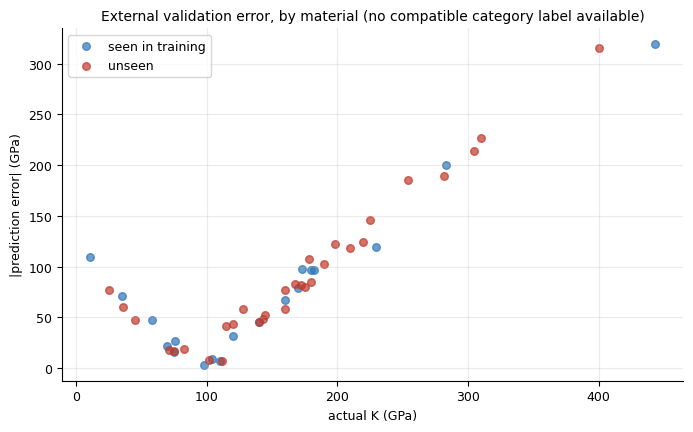

Consistent with 04: error is large relative to typical K values for BOTH seen and unseen reference materials --
the category-label mismatch (not just train/test overlap) is the dominant source of error here.


In [4]:
ref = pd.read_csv(TAB / "A6_reference_material_validation.csv")
ref["K_abs_err"] = (ref.K_actual - ref.K_pred).abs()
summary_ref = ref.groupby("in_training_data").agg(n=("Formula", "size"), median_K_actual=("K_actual", "median"), median_K_abs_err=("K_abs_err", "median"))
display(summary_ref)

fig, ax = plt.subplots(figsize=(7, 4.4))
for seen, label, color in [(True, "seen in training", "#2e75b6"), (False, "unseen", "#c0392b")]:
    sub = ref[ref.in_training_data == seen]
    ax.scatter(sub.K_actual, sub.K_abs_err, s=30, alpha=.7, color=color, label=label)
ax.set_xlabel("actual K (GPa)"); ax.set_ylabel("|prediction error| (GPa)"); ax.legend(); ax.set_title("External validation error, by material (no compatible category label available)")
savefig("09C_external_validation.png")
print("Consistent with 04: error is large relative to typical K values for BOTH seen and unseen reference materials --")
print("the category-label mismatch (not just train/test overlap) is the dominant source of error here.")

## Part D · Consolidated assumptions & limitations ledger
Every explicit assumption this project asked the reader to accept, gathered from 03, 05 and 07's own decision logs plus
the modelling choices made directly in 04-08, in one place.

In [5]:
fe_decisions = pd.read_csv(TAB / "feature_engineering_decisions.csv")
ledger = fe_decisions[["dataset", "PROBLEM", "DECISION"]].copy()
ledger["notebook"] = "03"
extra = pd.DataFrame([
    {"notebook": "04", "dataset": "DS1", "PROBLEM": "composition descriptors carry ~no documented signal (EDA)", "DECISION": "benchmark every model against the category-mean baseline; report when the model does NOT beat it (4 of 5 targets)"},
    {"notebook": "04", "dataset": "DS1", "PROBLEM": "external validation needs a category feature the reference materials don't have", "DECISION": "fall back to the overall training mean for the missing category-mean feature; report this as a materially harder, more honest test than in-sample CV"},
    {"notebook": "05", "dataset": "DS3/DS6", "PROBLEM": "unconstrained tree models were found to be non-monotonic in corrosion_rate (45.6% of rows)", "DECISION": "add monotonic_cst constraints to both the condition-rating and case-control models; re-verified in 08"},
    {"notebook": "05", "dataset": "DS6", "PROBLEM": "case-control sampling fraction (16.8%) is not the true population failure rate", "DECISION": "rescale relative_risk_score to the known population rate (1,011 failures / 19 yrs / 5,000 bridges) by mean-matching, not by trusting the raw classifier output"},
    {"notebook": "06", "dataset": "DS3", "PROBLEM": "no explicit $ notional per commodity to convert price-shock % into a $ market-risk number", "DECISION": "report commodity VaR/ES in % terms only; do not fabricate a notional"},
    {"notebook": "07", "dataset": "DS3/workbook", "PROBLEM": "workbook scenario asset IDs (BR-001, ...) do not exist in DS3's own ID scheme", "DECISION": "apply every scenario by categorical segment (is_metal, material contains 'Steel') instead of by named asset"},
    {"notebook": "08", "dataset": "DS3", "PROBLEM": "location and corrosion_environment turned out to be perfectly deterministic (not just correlated)", "DECISION": "flag as a simplification opportunity for a production version; left both in for this project since neither model's validity depends on removing the redundancy"},
])
ledger = pd.concat([ledger, extra], ignore_index=True)
ledger.to_csv(TAB / "final_assumptions_ledger.csv", index=False)
print(f"{len(ledger)} logged decisions across the project, {ledger.notebook.nunique()} notebooks")
display(ledger[["notebook", "dataset", "PROBLEM"]])

15 logged decisions across the project, 6 notebooks


,notebook,dataset,PROBLEM
0,03,DS1,density has no reliable physical identity from composition+cell volume (only...
1,03,DS1,"(K,G,nu) triplet mutually inconsistent with the README's own elastic identit..."
2,03,DS1,"band_gap_eV has a point mass at 0 (32.5% of rows, metals) alongside a contin..."
3,03,DS1,DS5 prices only 40 of the elements appearing in DS1 formulas; coverage is 32...
4,03,DS3,"remaining_thickness_mm, fatigue_cycles_millions and Paris constants are each..."
5,03,DS6,"5 columns (was_predicted, warning_lead_months, detected_by, insurance_claim_..."
6,03,DS6 vs DS3,DS6 has only failure events; there is no asset-level key to DS3 and no confi...
7,03,DS2,calendar-month seasonality is real (EDA A5) but computing the month mean ove...
8,04,DS1,composition descriptors carry ~no documented signal (EDA)
9,04,DS1,external validation needs a category feature the reference materials don't have


## Part E · Sign-off

In [6]:
signoff = pd.DataFrame([
    {"component": "DS1 material property models (04)", "status": "research-grade", "note": "beats category baseline on 1/5 targets (density, and even that rides on a physically backwards correlation); is_metal solved exactly; is_stable capped ~0.71-0.72 AUC without energy_above_hull_eV"},
    {"component": "DS3 condition-rating model (05)", "status": "usable with caveats", "note": "close to a 2-variable function of age+corrosion; monotonic by construction; not validated against any ground truth beyond the supplied labels"},
    {"component": "DS6 case-control failure classifier (05/08)", "status": "usable with caveats", "note": "AUC 0.74 vs 0.60 single-feature baseline; monotonic; PD calibration rests on the DS3-as-population assumption stated in 03 and repeated at every use"},
    {"component": "Financial risk engine (06)", "status": "usable with caveats", "note": "VaR/ES via historical simulation, no distributional assumption; credit EL/MC internally consistent; premiums ~10x computed EL with ~zero correlation to risk"},
    {"component": "Scenario stress testing (07)", "status": "demonstration-grade", "note": "mechanically sound and reuses 05/06's actual fitted models, but asset-level targeting is impossible with this data; segment-level shocks only"},
    {"component": "Interpretability (08)", "status": "complete", "note": "SHAP + partial dependence confirm the monotonic fixes hold and explain the density model's backwards finding at the prediction level"},
])
signoff.to_csv(TAB / "final_signoff.csv", index=False)
display(signoff)

print("\nWhat would most improve this project, in priority order:")
print("1. An asset-level key between DS3 and DS6 (the single biggest limitation -- everything in 05-07's credit book")
print("   inherits the case-control assumption because this doesn't exist).")
print("2. A commodity notional/exposure table, to turn 06/07's % market-risk numbers into $ figures.")
print("3. Real crystal-structure data (atomic positions, bonds) for DS1, which is what would actually let a CGNN beat")
print("   the category-mean baseline -- flat composition descriptors structurally cannot, per 02's own EDA finding.")

,component,status,note
0,DS1 material property models (04),research-grade,"beats category baseline on 1/5 targets (density, and even that rides on a ph..."
1,DS3 condition-rating model (05),usable with caveats,close to a 2-variable function of age+corrosion; monotonic by construction; ...
2,DS6 case-control failure classifier (05/08),usable with caveats,AUC 0.74 vs 0.60 single-feature baseline; monotonic; PD calibration rests on...
3,Financial risk engine (06),usable with caveats,"VaR/ES via historical simulation, no distributional assumption; credit EL/MC..."
4,Scenario stress testing (07),demonstration-grade,"mechanically sound and reuses 05/06's actual fitted models, but asset-level ..."
5,Interpretability (08),complete,SHAP + partial dependence confirm the monotonic fixes hold and explain the d...



What would most improve this project, in priority order:
1. An asset-level key between DS3 and DS6 (the single biggest limitation -- everything in 05-07's credit book
   inherits the case-control assumption because this doesn't exist).
2. A commodity notional/exposure table, to turn 06/07's % market-risk numbers into $ figures.
3. Real crystal-structure data (atomic positions, bonds) for DS1, which is what would actually let a CGNN beat
   the category-mean baseline -- flat composition descriptors structurally cannot, per 02's own EDA finding.


## Project summary
Nine notebooks, starting from an audit of what the data actually contains and ending at a stress-tested, internally
consistent (if honestly-limited) risk engine:

- **01-02** audited and explored six datasets + a reference workbook, producing the leakage and redundancy findings
  every later notebook had to respect.
- **03** turned those findings into five feature stores and a column-level manifest (`feature_manifest.csv`) that acted
  as the contract for everything after it.
- **04** trained and honestly benchmarked DS1's material property models — the headline finding being that a plain
  category lookup beats a trained model on 4 of 5 targets, not a failure to fix with more modelling.
- **05** built the degradation and case-control failure models, catching and fixing a real monotonicity bug along the way.
- **06** combined those into a financial risk engine (market VaR/ES, credit PD×LGD×EAD, Monte Carlo).
- **07** ran the workbook's five named stress scenarios through 05/06's actual fitted models.
- **08** verified with SHAP and partial dependence that 05's fix actually worked, and explained 04's oddest finding
  at the individual-prediction level.
- **09** (this notebook) rolled all of it into one scorecard, one consistency check (Part B, re-verified from the files
  actually on disk), one assumptions ledger, and one sign-off — every assumption that risk number depends on is written
  down in `final_assumptions_ledger.csv`, not buried in a markdown cell three notebooks back.